# Financial agent and evaluator-optimizer

This notebook shows my part of the system. First the financial agent analyzes one ticker with Yahoo Finance data. Then the full system runs (coordinator, financial agent and news agent), and the evaluator-optimizer scores the final answer, gives feedback and rewrites it.

Ollama needs to be running with `llama3.2` pulled (see the README).

In [1]:
import textwrap

import pandas as pd
import matplotlib.pyplot as plt

from agent_memory import AgentMemory
from coordinator_agent import run_research
from data_loader import load_prices
from evaluator import evaluate_and_optimize, unsupported_numbers
from financial_agent import analyze_financials
from news_agent import analyze_news

TICKER = "AAPL"
QUESTION = "Analyze Apple's recent financial performance and news."


def show(text, width=100):
    print(textwrap.fill(text, width))

## 1. Financial agent

`analyze_financials` loads one year of prices, the latest annual statements and the valuation numbers, calculates the metrics, and asks llama3.2 for a short summary that can only use those numbers.

In [2]:
financial = analyze_financials(TICKER)

print(financial["company"], "|", financial["sector"], "|", financial["industry"])
print("Price data from", financial["period"]["start"], "to", financial["as_of"],
      f"({financial['period']['trading_days']} trading days)")
print("Trend:", financial["price_trend"])
print()
show(financial["summary"])

Apple Inc. | Technology | Consumer Electronics
Price data from 2025-10-16 to 2026-10-15 (251 trading days)
Trend: uptrend

As of October 15, 2026, Apple Inc. has experienced an uptrend in price, with a latest price of
$342.00. The company's revenue grew by 6.43% from fiscal year end 2025 to $416.16 billion. Its net
income was $112.01 billion and market capitalization stands at $4991.21 billion.


In [3]:
tables = {
    "Price and risk": financial["metrics"],
    f"Fundamentals (FY ending {financial['fundamentals'].get('fiscal_year_end')})": {
        k: v for k, v in financial["fundamentals"].items() if k != "fiscal_year_end"},
    "Valuation (Yahoo Finance, at run time)": financial["valuation"],
}
for title, values in tables.items():
    print(title)
    display(pd.Series(values, name="value").to_frame())

Price and risk


,value
latest_price,342.00
return_1y_pct,38.72
return_3m_pct,2.56
return_1m_pct,2.88
volatility_1y_pct,24.46
max_drawdown_1y_pct,-13.80
high_52w,348.15
low_52w,242.76
pct_below_52w_high,1.77
sma_50,325.07


Fundamentals (FY ending 2025-09-30)


,value
revenue_bn,416.16
revenue_growth_pct,6.43
net_income_bn,112.01
gross_margin_pct,46.91
operating_margin_pct,31.97
net_margin_pct,26.92
free_cash_flow_bn,98.77
debt_to_equity,1.34
current_ratio,0.89


Valuation (Yahoo Finance, at run time)


,value
market_cap_bn,4991.21
trailing_pe,39.13
forward_pe,35.71
price_to_book,46.47
beta,1.07


In [4]:
print("Limitations:")
for note in financial["limitations"]:
    print("-", note)

Limitations:
- Prices are daily bars from Yahoo Finance, adjusted for splits and dividends. If the market is open, the latest bar may be an intraday price.
- All metrics describe past performance and are not a forecast.
- Statement figures come from the latest annual report (fiscal year ending 2025-09-30), not the latest quarter, and are in the company's reporting currency.
- Valuation multiples (market cap, P/E, price-to-book, beta) are Yahoo Finance snapshots at run time.


## 2. Price chart

Closing price for the same period with the 50-day and 200-day moving averages. The trend label above compares the latest price with the 200-day average.

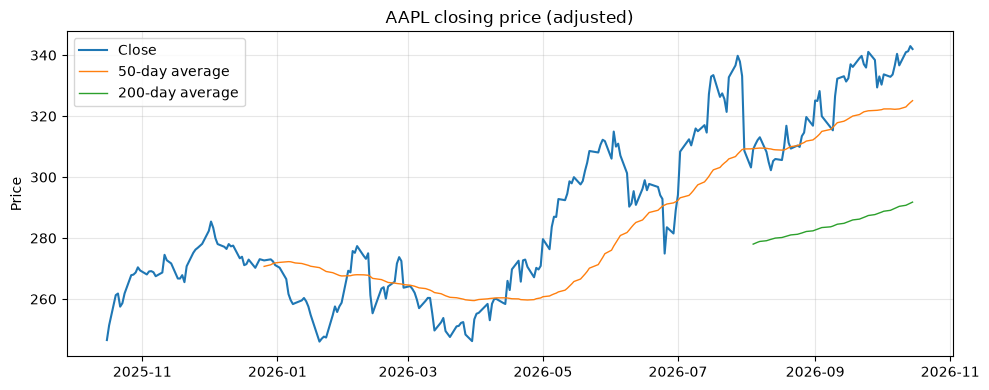

In [5]:
prices = load_prices(TICKER, period="1y")
close = prices["Close"]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(close.index, close, label="Close", linewidth=1.5)
ax.plot(close.index, close.rolling(50).mean(), label="50-day average", linewidth=1)
ax.plot(close.index, close.rolling(200).mean(), label="200-day average", linewidth=1)
ax.set_title(f"{TICKER} closing price (adjusted)")
ax.set_ylabel("Price")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## 3. Grounding check

The evaluator checks every number in a piece of text against the data. Here it is given one sentence that uses real numbers and one that makes numbers up.

In [6]:
m = financial["metrics"]
real = f"{TICKER} closed at ${m['latest_price']} and returned {m['return_1y_pct']}% over the year."
made_up = f"{TICKER} closed at $512.40 and returned 61.5% over the year."

for label, text in [("Real numbers", real), ("Made-up numbers", made_up)]:
    print(f"{label}: {text}")
    print("  numbers not found in the data:", unsupported_numbers(text, financial))

Real numbers: AAPL closed at $342.0 and returned 38.72% over the year.
  numbers not found in the data: []
Made-up numbers: AAPL closed at $512.40 and returned 61.5% over the year.
  numbers not found in the data: ['512.40', '61.5%']


## 4. Full system and evaluator-optimizer

The coordinator plans the research and calls the financial and news agents. Then `evaluate_and_optimize` writes an answer, scores it on completeness, grounding and clarity (1 to 5), gives feedback and rewrites it. It stops when the answer passes, after 3 rounds, or when a rewrite comes back unchanged, and it keeps the best-scoring draft. A full run takes a few minutes.

In [7]:
report = run_research(
    TICKER, QUESTION,
    news_agent=analyze_news,
    financial_agent=analyze_financials,
    memory=AgentMemory(),
)
print("Routes chosen by the coordinator:", report["plan"]["routes"])
print("Process complete:", report["reflection"]["complete"])

Routes chosen by the coordinator: ['financial', 'news']
Process complete: False


In [8]:
evaluated = evaluate_and_optimize(report)

rounds = pd.DataFrame([
    {"round": step["iteration"], **step["scores"], "passed": step["passed"],
     "rule issues": step["rule_issues"], "words": len(step["analysis"].split())}
    for step in evaluated["iterations"]
]).set_index("round")
rounds

,completeness,grounding,clarity,overall,passed,rule issues,words
round,,,,,,,
1,3,5,3,3.67,False,1,101
2,3,3,5,3.67,False,1,124
3,4,3,4,3.67,False,0,162


In [9]:
for step in evaluated["iterations"]:
    print(f"Round {step['iteration']}  scores: {step['scores']}")
    show(step["analysis"])
    print("Feedback:")
    for item in step["feedback"] or ["(none)"]:
        print(textwrap.fill(item, 100, initial_indent="  - ", subsequent_indent="    "))
    print()

Round 1  scores: {'completeness': 3, 'grounding': 5, 'clarity': 3, 'overall': 3.67}
As of October 15, 2026, Apple Inc. has experienced an uptrend in price with a latest price of
$342.00. The company's revenue grew by 6.43% from fiscal year end 2025 to $416.16 billion. Its net
income was $112.01 billion and market capitalization stands at $4991.21 billion. Apple's audience is
considered worth paying for, according to Jim Cramer, as reported on October 16, 2026. However, the
exact financial implications of this statement are not specified. The analysis has limitations due
to prices being daily bars from Yahoo Finance and valuation multiples being snapshots at run time.
Sentiment analysis may contain classification errors.
Feedback:
  - Cover the news results: say the overall news sentiment (neutral) and what the headlines
    reported.
  - The company's revenue grew by 6.43% from fiscal year end 2025 to $416.16 billion. This statement
    should be supported with a specific date and figu

In [10]:
print(f"Selected draft: round {evaluated['selected_iteration']} "
      f"(passed: {evaluated['passed']}, loop stopped because: {evaluated['stop_reason']})")
print()
show(evaluated["report"]["final_analysis"])

Selected draft: round 3 (passed: False, loop stopped because: max_iterations)

As of October 15, 2026, Apple Inc. has experienced an uptrend in price with a latest price of
$342.00. The company's revenue grew by 6.43% from fiscal year end 2025 to $416.16 billion. Its net
income was $112.01 billion and market capitalization stands at $4991.21 billion. According to
Stocktwits, Jim Cramer states that Apple's audience is worth paying for on October 16, 2026.
However, the exact financial implications of this statement are not specified. The analysis has
limitations due to prices being daily bars from Yahoo Finance and valuation multiples being
snapshots at run time. Sentiment analysis may contain classification errors. Main limitations
include reliance on headlines and available summaries, which may not be verified full-text articles,
and potential classification errors in sentiment analysis. The overall news sentiment is neutral,
with the headline reporting that Jim Cramer says Apple's aud

## Notes

- llama3.2 is a small model, so a draft often does not reach a score of 4 on every dimension. In that case the loop stops after 3 rounds and keeps the best draft.
- The rule checks in `evaluator.py` cap the reviewer's scores when the text uses numbers that are not in the data, leaves out an agent's results, skips the price date, or gives investment advice.
- Results change from run to run because prices, news and the model's wording change.